# ME7200 – Exploración de datos FEMTO / PRONOSTIA para predicción de RUL

Este notebook muestra cómo descargar, cargar y graficar datos del dataset **FEMTO / PRONOSTIA** usando la librería `rul-datasets`.

El objetivo es preparar una base para una tarea de predicción de **Vida Útil Remanente (RUL)** en rodamientos.

En este notebook se revisa:

1. Instalación de librerías.
2. Carga de datos FEMTO.
3. Visualización de ventanas de vibración.
4. Evolución del RUL.
5. Cálculo de indicadores temporales básicos.
6. Comparación entre rodamientos.

In [ ]:
# ============================================================
# 1. Instalación de librerías
# ============================================================

!pip -q install rul-datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rul_datasets

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 2. Carga del dataset FEMTO / PRONOSTIA

FEMTO/PRONOSTIA contiene ensayos de rodamientos monitoreados hasta falla.  
Cada ensayo corresponde a una serie temporal de vibración.

La librería `rul-datasets` permite cargar los datos directamente en formato de ventanas temporales.

En este ejemplo se usa:

- `fd = 1`: condición de operación 1.
- `window_size = 2560`: largo de cada ventana temporal.

Puedes cambiar `FD = 1` por `FD = 2` o `FD = 3` para trabajar con otra condición operacional.

In [ ]:
# ============================================================
# 2. Carga del dataset FEMTO / PRONOSTIA
# ============================================================

FD = 1
WINDOW_SIZE = 2560

reader = rul_datasets.reader.FemtoReader(
    fd=FD,
    window_size=WINDOW_SIZE
)

# Este paso descarga/prepara los datos si no están disponibles localmente.
reader.prepare_data()

X_dev, y_dev = reader.load_split("dev")
X_val, y_val = reader.load_split("val")
X_test, y_test = reader.load_split("test")

print("Condición operacional FD:", FD)
print("Tamaño de ventana:", WINDOW_SIZE)

print("Número de rodamientos en dev :", len(X_dev))
print("Número de rodamientos en val :", len(X_val))
print("Número de rodamientos en test:", len(X_test))

print("Forma del primer rodamiento de entrenamiento:")
print("X_dev[0]:", X_dev[0].shape)
print("y_dev[0]:", y_dev[0].shape)

print("Forma del primer rodamiento de validación:")
print("X_val[0]:", X_val[0].shape)
print("y_val[0]:", y_val[0].shape)

print("Forma del primer rodamiento de testo:")
print("X_test[0]:", X_test[0].shape)
print("y_test[0]:", y_test[0].shape)

Condición operacional FD: 1
Tamaño de ventana: 2560
Número de rodamientos en dev : 2
Número de rodamientos en val : 1
Número de rodamientos en test: 4
Forma del primer rodamiento de entrenamiento:
X_dev[0]: (2803, 2560, 2)
y_dev[0]: (2803,)
Forma del primer rodamiento de validación:
X_val[0]: (2375, 2560, 2)
y_val[0]: (2375,)
Forma del primer rodamiento de testo:
X_test[0]: (1428, 2560, 2)
y_test[0]: (1428,)


## 3. Interpretación de la estructura de datos

Cada elemento de `X_dev` corresponde a un rodamiento.

La forma típica de cada rodamiento es:

```text
(número de ventanas, largo de ventana, número de canales)
```

En este caso, cada ventana contiene señales de vibración con dos canales de aceleración.

La variable `y_dev` contiene el **RUL asociado a cada ventana**.

In [ ]:
# ============================================================
# 3. Resumen de rodamientos disponibles
# ============================================================

summary = []

for split_name, X_split, y_split in [
    ("dev", X_dev, y_dev),
    ("val", X_val, y_val),
    ("test", X_test, y_test)
]:
    for i, (X_bearing, y_bearing) in enumerate(zip(X_split, y_split)):
        summary.append({
            "split": split_name,
            "bearing_id": i,
            "n_windows": X_bearing.shape[0],
            "window_size": X_bearing.shape[1],
            "n_channels": X_bearing.shape[2],
            "RUL_inicial": float(y_bearing[0]),
            "RUL_final": float(y_bearing[-1])
        })

summary_df = pd.DataFrame(summary)
display(summary_df)

,split,bearing_id,n_windows,window_size,n_channels,RUL_inicial,RUL_final
0,dev,0,2803,2560,2,2803.0,1.0
1,dev,1,871,2560,2,871.0,1.0
2,val,0,2375,2560,2,2375.0,1.0
3,test,0,1428,2560,2,1428.0,1.0
4,test,1,2463,2560,2,2463.0,1.0
5,test,2,2448,2560,2,2448.0,1.0
6,test,3,2259,2560,2,2259.0,1.0


## 4. Evolución del RUL

> Agregar bloque entrecomillado



El RUL disminuye a medida que el rodamiento avanza hacia la falla.

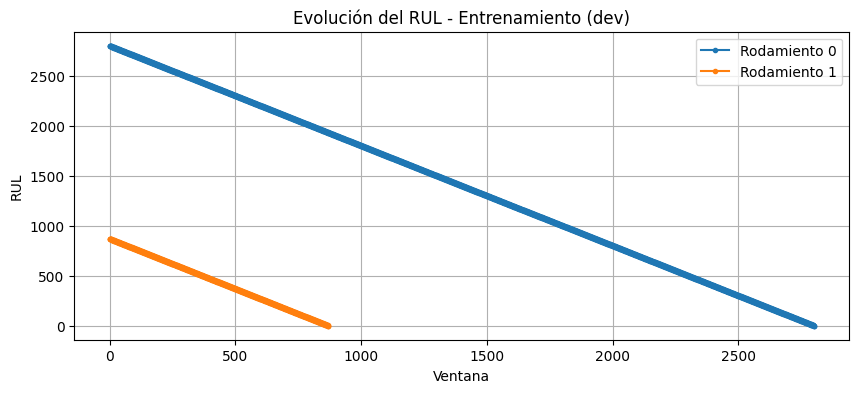

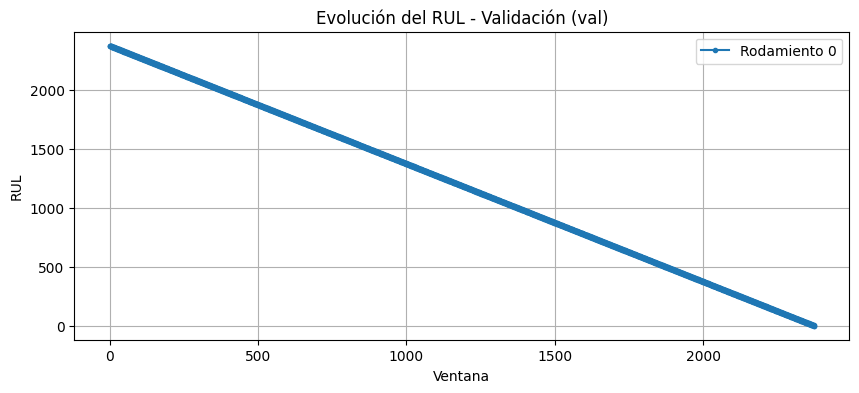

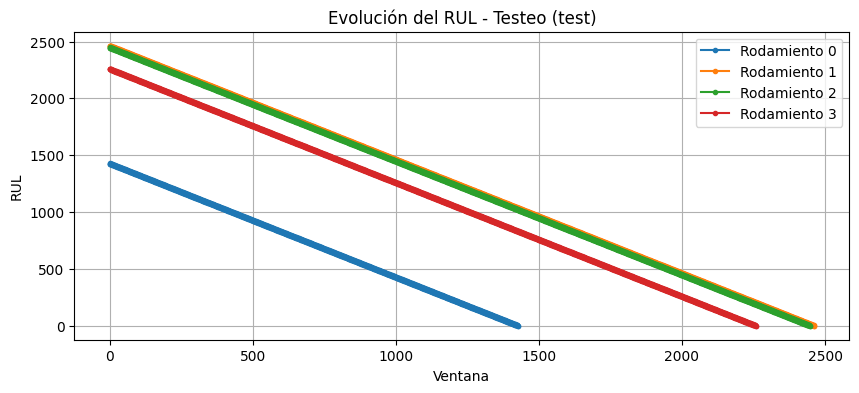

In [ ]:
# ============================================================
# 4. Gráficos del RUL para entrenamiento, validación y testeo
# ============================================================

splits = {
    "Entrenamiento (dev)": y_dev,
    "Validación (val)": y_val,
    "Testeo (test)": y_test
}

for split_label, y_split in splits.items():

    plt.figure(figsize=(10, 4))

    for bearing_id, y_bearing in enumerate(y_split):
        plt.plot(
            y_bearing,
            marker=".",
            linewidth=1.5,
            label=f"Rodamiento {bearing_id}"
        )

    plt.title(f"Evolución del RUL - {split_label}")
    plt.xlabel("Ventana")
    plt.ylabel("RUL")
    plt.grid(True)
    plt.legend()
    plt.show()

## 5. Comparar ventanas al inicio, mitad y final de la vida

Una forma simple de observar la degradación es comparar señales de vibración en distintos momentos de la vida del rodamiento.

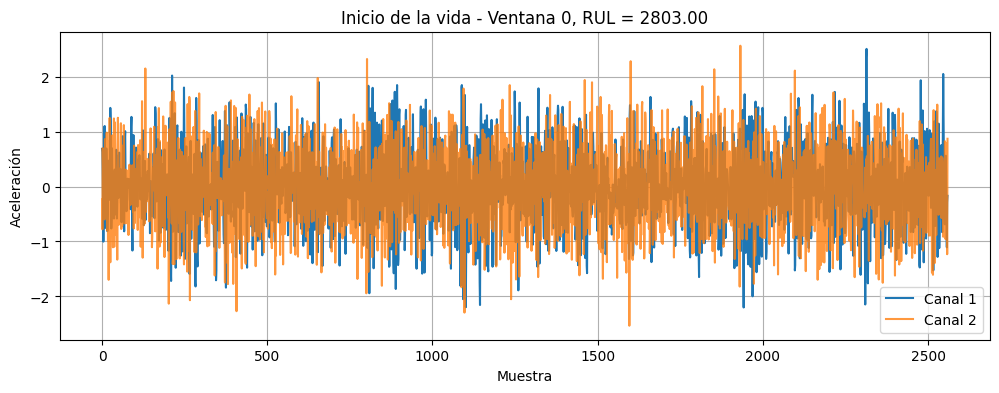

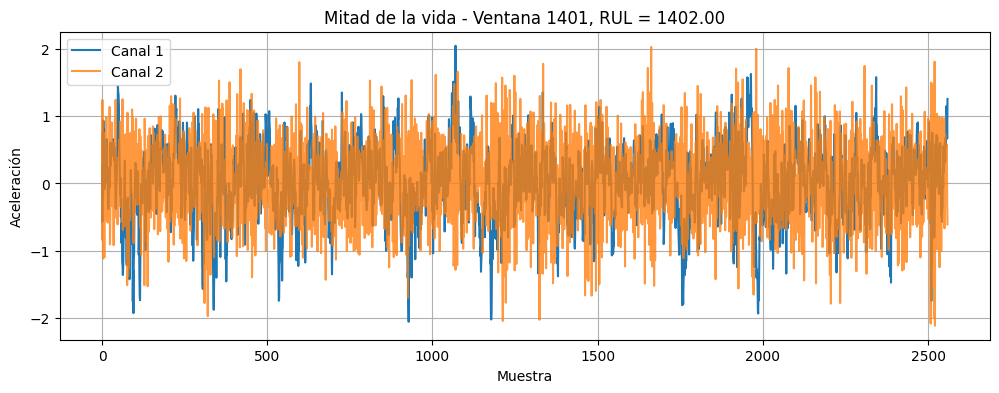

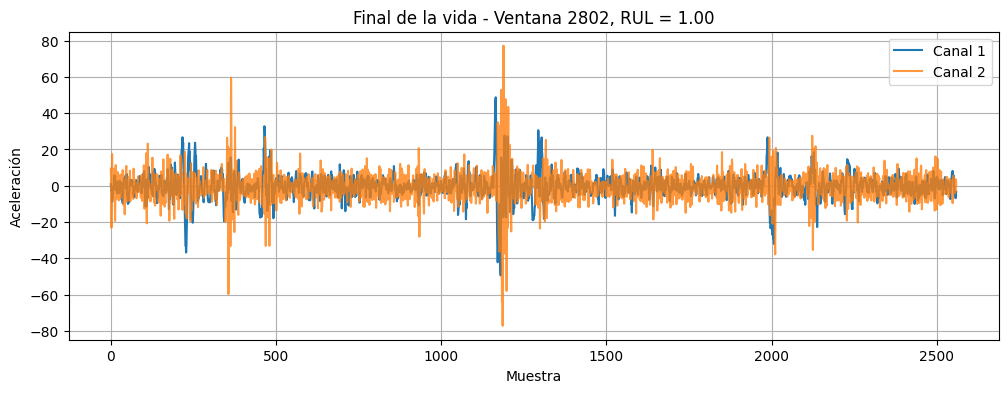

In [ ]:
# ============================================================
# 5. Ventanas al inicio, mitad y final de la vida
# ============================================================

bearing_id = 0
X_bearing = X_dev[bearing_id]
y_bearing = y_dev[bearing_id]

window_indices = [0, len(X_bearing)//2, len(X_bearing)-1]
window_names = ["Inicio", "Mitad", "Final"]

for idx, name in zip(window_indices, window_names):
    signal = X_bearing[idx]
    rul_value = y_bearing[idx]

    plt.figure(figsize=(12, 4))
    plt.plot(signal[:, 0], label="Canal 1")
    plt.plot(signal[:, 1], label="Canal 2", alpha=0.8)
    plt.title(f"{name} de la vida - Ventana {idx}, RUL = {rul_value:.2f}")
    plt.xlabel("Muestra")
    plt.ylabel("Aceleración")
    plt.legend()
    plt.show()

## 7. Indicadores temporales de vibración

A partir de cada ventana se pueden calcular indicadores de condición, por ejemplo:

- RMS.
- Peak-to-peak.
- Factor de cresta.
- Kurtosis.

Estos indicadores pueden usarse luego como variables de entrada para modelos de regresión de RUL.

In [ ]:
# ============================================================
# 7. Funciones para indicadores temporales
# ============================================================

def rms(x):
    return np.sqrt(np.mean(x**2, axis=1))

def peak_to_peak(x):
    return np.max(x, axis=1) - np.min(x, axis=1)

def crest_factor(x):
    return np.max(np.abs(x), axis=1) / (rms(x) + 1e-12)

def kurtosis_manual(x):
    mu = np.mean(x, axis=1, keepdims=True)
    sigma = np.std(x, axis=1, keepdims=True) + 1e-12
    z = (x - mu) / sigma
    return np.mean(z**4, axis=1)

print("Funciones definidas")

Funciones definidas


In [ ]:
# ============================================================
# 8. Calcular indicadores para un rodamiento
# ============================================================

bearing_id = 0
channel = 0

X_bearing = X_dev[bearing_id]
y_bearing = y_dev[bearing_id]

x = X_bearing[:, :, channel]

features_df = pd.DataFrame({
    "RUL": y_bearing,
    "RMS": rms(x),
    "Peak_to_peak": peak_to_peak(x),
    "Crest_factor": crest_factor(x),
    "Kurtosis": kurtosis_manual(x)
})

display(features_df.head())

,RUL,RMS,Peak_to_peak,Crest_factor,Kurtosis
0,2803.0,0.701137,4.709276,3.576305,2.868535
1,2802.0,0.667889,4.543271,3.580707,2.915354
2,2801.0,0.662957,4.589453,3.580988,3.033388
3,2800.0,0.692521,4.727998,3.444333,3.043419
4,2799.0,0.707274,4.277415,3.116441,2.814523


## 8. Graficar indicadores respecto al RUL

En estos gráficos el eje horizontal se invierte para que la degradación avance visualmente desde izquierda a derecha, es decir, desde mayor RUL hacia menor RUL.

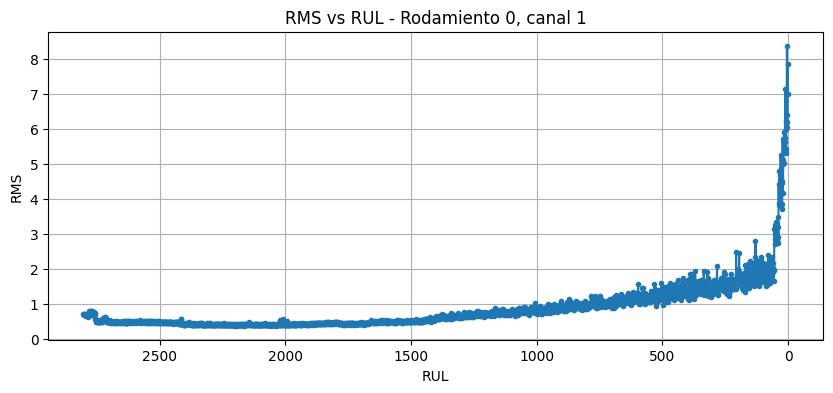

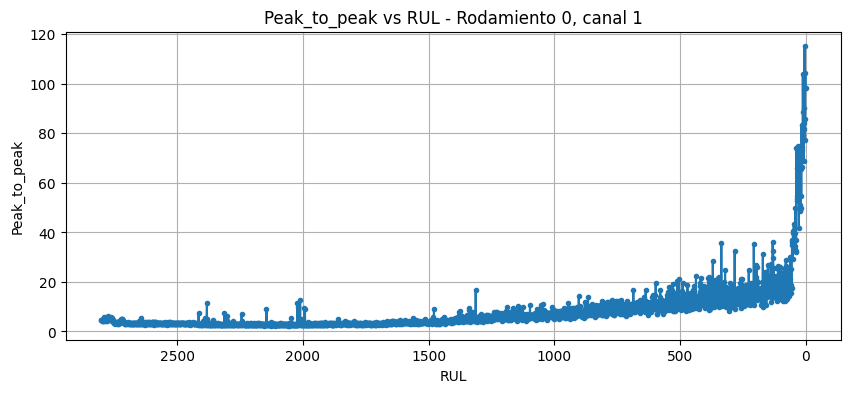

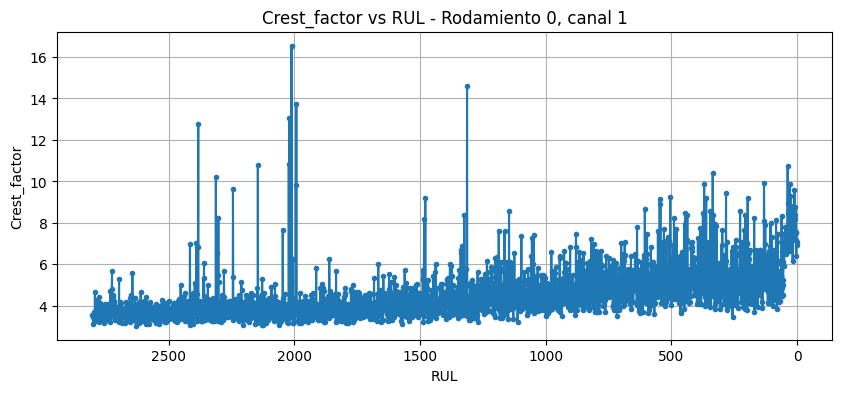

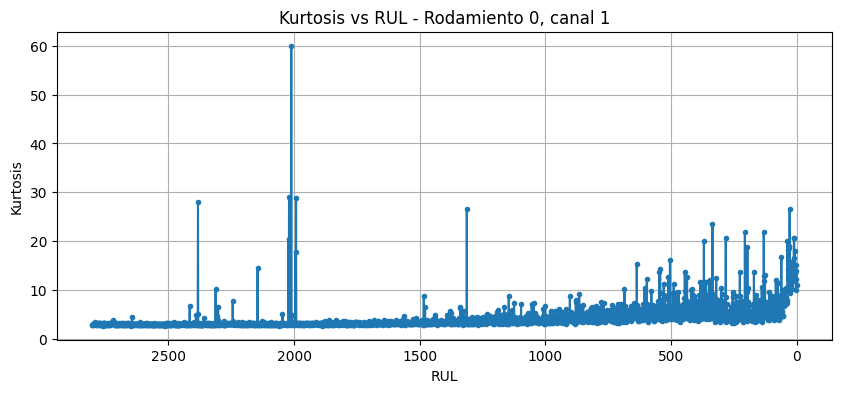

In [ ]:
# ============================================================
# 9. Indicadores vs RUL
# ============================================================

indicators = ["RMS", "Peak_to_peak", "Crest_factor", "Kurtosis"]

for indicator in indicators:
    plt.figure(figsize=(10, 4))
    plt.plot(features_df["RUL"], features_df[indicator], marker=".")
    plt.gca().invert_xaxis()
    plt.title(f"{indicator} vs RUL - Rodamiento {bearing_id}, canal {channel + 1}")
    plt.xlabel("RUL")
    plt.ylabel(indicator)
    plt.show()

## 9. Comparación entre rodamientos

A continuación se compara la evolución del RMS en todos los rodamientos del conjunto `dev`.

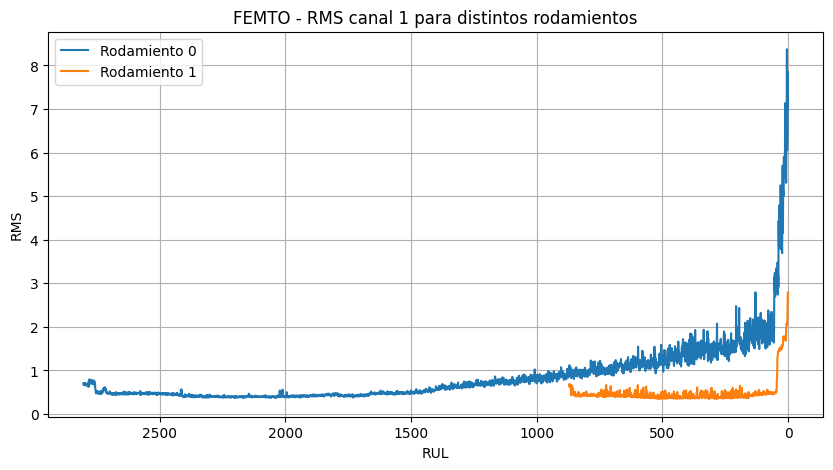

In [ ]:
# ============================================================
# 10. Comparar RMS entre rodamientos
# ============================================================

channel = 0

plt.figure(figsize=(10, 5))

for bearing_id in range(len(X_dev)):
    X_bearing = X_dev[bearing_id]
    y_bearing = y_dev[bearing_id]
    x = X_bearing[:, :, channel]
    rms_values = rms(x)

    plt.plot(y_bearing, rms_values, label=f"Rodamiento {bearing_id}")

plt.gca().invert_xaxis()
plt.title("FEMTO - RMS canal 1 para distintos rodamientos")
plt.xlabel("RUL")
plt.ylabel("RMS")
plt.legend()
plt.show()

Forma de X_train_feat: (3674, 3)
Regresión Lineal -> MAE: 702.33 | RMSE: 1001.74 | R2: -1.1768
Árbol de Regresión -> MAE: 667.71 | RMSE: 825.56 | R2: -0.4785
Random Forest -> MAE: 633.40 | RMSE: 780.69 | R2: -0.3221
XGBoost -> MAE: 622.52 | RMSE: 772.85 | R2: -0.2957


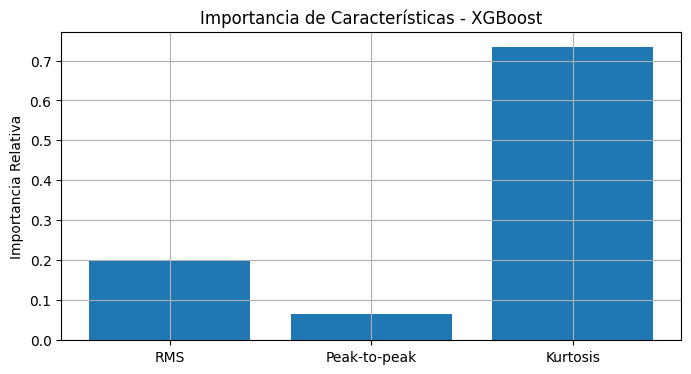

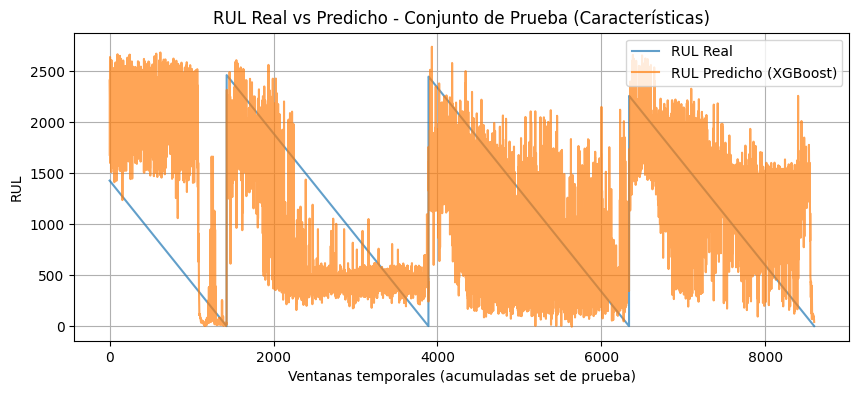

Input LSTM shape: (3674, 2560, 2)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - loss: 2038983.1250 - mae: 1164.4178 - val_loss: 1818046.2500 - val_mae: 1161.4176
Epoch 2/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - loss: 1944665.3750 - mae: 1124.5248 - val_loss: 1705400.1250 - val_mae: 1114.0234
Epoch 3/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - loss: 1818381.6250 - mae: 1071.9498 - val_loss: 1561429.5000 - val_mae: 1053.4003
Epoch 4/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - loss: 1664026.0000 - mae: 1008.5917 - val_loss: 1394008.7500 - val_mae: 982.8928
Epoch 5/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - loss: 1493693.5000 - mae: 940.5285 - val_loss: 1217297.6250 - val_mae: 908.3757
Epoch 6/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - loss: 1322290.5000 - mae: 874.9856 - val_loss: 1043469.8750 - val_mae: 834.8114
Epoch 7/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - loss: 1157522.6250 - mae: 815.9260 - val_loss: 882676.0625 - val_mae: 765.4678
Epoch 8/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - loss: 1030894.8

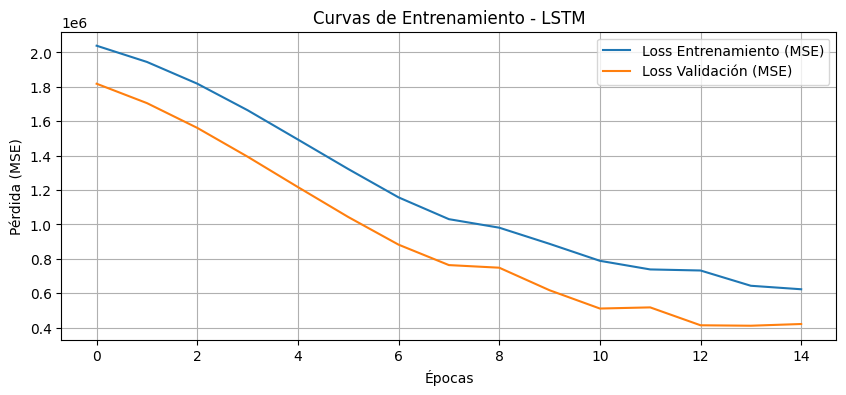

269/269 ━━━━━━━━━━━━━━━━━━━━ 72s 269ms/step
LSTM -> MAE: 542.87 | RMSE: 648.48 | R2: 0.0878


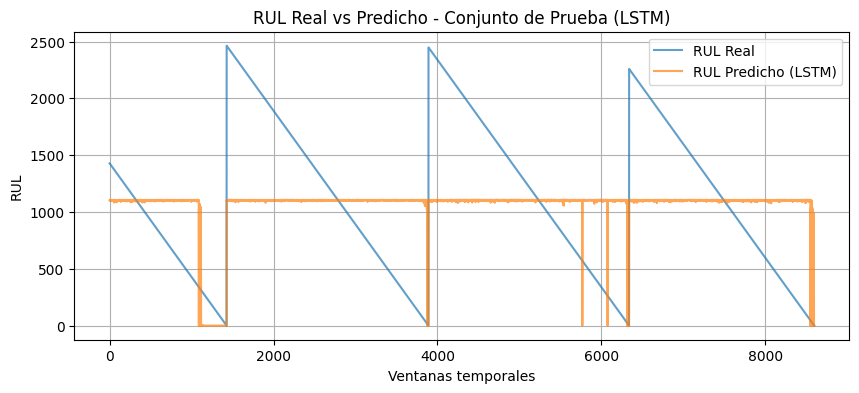

In [ ]:
# ============================================================
# PARTE 2 y 3: Preparación de Datos y Modelos Tradicionales
# ============================================================
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Función para extraer características de todos los rodamientos de un split
def extract_features_for_split(X_split, y_split, channel=0):
    features_list = []
    ruls_list = []
    for X_bearing, y_bearing in zip(X_split, y_split):
        x = X_bearing[:, :, channel]
        feat_matrix = np.column_stack((rms(x), peak_to_peak(x), kurtosis_manual(x)))
        features_list.append(feat_matrix)
        # CORRECCIÓN: Forzamos a que y_bearing sea al menos de 1 dimensión
        ruls_list.append(np.atleast_1d(y_bearing).flatten())

    # Concatenamos para crear un solo dataset tabular
    return np.vstack(features_list), np.concatenate(ruls_list)

# Evitamos fuga de información separando por rodamientos (dev -> train, test -> test)
X_train_feat, y_train = extract_features_for_split(X_dev, y_dev)
X_val_feat, y_val = extract_features_for_split(X_val, y_val)
X_test_feat, y_test = extract_features_for_split(X_test, y_test)

print(f"Forma de X_train_feat: {X_train_feat.shape}")

# Definición de Modelos Tradicionales
models = {
    "Regresión Lineal": LinearRegression(),
    "Árbol de Regresión": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42)
}

results = {}

# Entrenamiento y evaluación
for name, model in models.items():
    model.fit(X_train_feat, y_train)
    y_pred = model.predict(X_test_feat)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}
    print(f"{name} -> MAE: {mae:.2f} | RMSE: {rmse:.2f} | R2: {r2:.4f}")

# Gráfico de Importancia de Variables para XGBoost
xgb_model = models["XGBoost"]
plt.figure(figsize=(8, 4))
plt.bar(["RMS", "Peak-to-peak", "Kurtosis"], xgb_model.feature_importances_)
plt.title("Importancia de Características - XGBoost")
plt.ylabel("Importancia Relativa")
plt.show()

# Gráfico Real vs Predicho (XGBoost como ejemplo de características)
plt.figure(figsize=(10, 4))
plt.plot(y_test, label="RUL Real", alpha=0.7)
plt.plot(models["XGBoost"].predict(X_test_feat), label="RUL Predicho (XGBoost)", alpha=0.7)
plt.title("RUL Real vs Predicho - Conjunto de Prueba (Características)")
plt.xlabel("Ventanas temporales (acumuladas set de prueba)")
plt.ylabel("RUL")
plt.legend()
plt.show()


# ============================================================
# PARTE 4: Modelo LSTM para predicción de RUL
# ============================================================
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Corrección para evitar el error de dimensiones
X_train_lstm = np.concatenate([x for x in X_dev], axis=0)
y_train_lstm = np.concatenate([np.atleast_1d(y) for y in y_dev], axis=0)

X_val_lstm = np.concatenate([x for x in X_val], axis=0)
y_val_lstm = np.concatenate([np.atleast_1d(y) for y in y_val], axis=0)

X_test_lstm = np.concatenate([x for x in X_test], axis=0)
y_test_lstm = np.concatenate([np.atleast_1d(y) for y in y_test], axis=0)

print(f"Input LSTM shape: {X_train_lstm.shape}")

# Construcción de la arquitectura LSTM
lstm_model = Sequential([
    LSTM(64, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# Entrenamiento
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    validation_data=(X_val_lstm, y_val_lstm),
    epochs=15,
    batch_size=64,
    verbose=1
)

# Gráfica de entrenamiento LSTM
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Loss Entrenamiento (MSE)')
plt.plot(history.history['val_loss'], label='Loss Validación (MSE)')
plt.title("Curvas de Entrenamiento - LSTM")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (MSE)")
plt.legend()
plt.show()

# Evaluación LSTM
y_pred_lstm = lstm_model.predict(X_test_lstm).flatten()
mae_lstm = mean_absolute_error(y_test_lstm, y_pred_lstm)
rmse_lstm = np.sqrt(mean_squared_error(y_test_lstm, y_pred_lstm))
r2_lstm = r2_score(y_test_lstm, y_pred_lstm)

print(f"LSTM -> MAE: {mae_lstm:.2f} | RMSE: {rmse_lstm:.2f} | R2: {r2_lstm:.4f}")

# Gráfico Real vs Predicho LSTM
plt.figure(figsize=(10, 4))
plt.plot(y_test_lstm, label="RUL Real", alpha=0.7)
plt.plot(y_pred_lstm, label="RUL Predicho (LSTM)", alpha=0.7)
plt.title("RUL Real vs Predicho - Conjunto de Prueba (LSTM)")
plt.xlabel("Ventanas temporales")
plt.ylabel("RUL")
plt.legend()
plt.show()